# Z40 — analiza widm gamma i aktywacji Au

Notebook odtwarza obróbkę danych z `cwiczenia/Z40_34/data/raw/`. Jest częścią analizy, a nie tekstem sprawozdania. Wykorzystuje pomiary wykonane w laboratorium: kontrolę Cs/Co, widma Eu, Mn, Na, I, monet, Au i Cu oraz długi pomiar tła. Dla Au i Cu oblicza dwa warunkowe wyniki strumienia neutronów.

Uruchom komórki po kolei. W lokalnej kopii repozytorium pliki są znajdowane automatycznie. W Colab otwórz ten notebook, wykonaj komórkę poniżej i prześlij ZIP z katalogiem `cwiczenia/Z40_34/data/raw/` lub samym `data/raw/`. Nie przesyłaj tokenu GitHub do notebooka. Kod nie modyfikuje plików surowych.

Wartości aktywacji z notatek: Au `m=0,1328 g`, około `t_a=3,5 h`, `t_c=61 s` przed pierwszym pomiarem i `1084 s` przed drugim według relacji (z nagłówków wynika 1077 s); Cu `m=0,1479 g`, około `t_a=4 h`, `t_c≈60 s`. Wydajność z trzeciego Eu dotyczy odległości około 16,9 cm od obudowy; druga folia Au i Cu leżały na obudowie.

**Granice wyniku:** obliczony z Au strumień jest lokalną gęstością strumienia w modelu z instrukcji, nie całkowitą emisją AmBe. Nieznana geometria detektora i widmo neutronów ograniczają wartość bezwzględną. Wynik warunkowy i scenariusze są jawnie rozdzielone od niepewności statystycznej.

In [1]:
from pathlib import Path
import os, re, struct, hashlib, zipfile
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.special import ndtr
try:
    from IPython.display import display
except ImportError:  # zwykły interpreter Python do testów poza Jupyterem
    display = print

pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": .25})

def find_project():
    override = os.environ.get("Z40_DATA_ROOT")
    if override:
        p = Path(override).expanduser().resolve()
        if p.is_dir():
            return p.parent.parent, p
        raise FileNotFoundError(f"Nie istnieje Z40_DATA_ROOT={p}")
    for start in (Path.cwd(), Path("/content")):
        for parent in (start, *start.parents):
            for project in (parent, parent / "cwiczenia" / "Z40_34"):
                raw = project / "data" / "raw"
                if (raw / "pomiar_tlo_2026_10_23.dat").is_file():
                    return project, raw
    return None, None

PROJECT, RAW = find_project()
if RAW is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Uruchom z repozytorium albo ustaw Z40_DATA_ROOT na katalog data/raw."
        ) from exc
    print("Prześlij ZIP z data/raw (z katalogiem nadrzędnym lub bez).")
    uploaded = files.upload()
    if len(uploaded) != 1 or not next(iter(uploaded)).lower().endswith(".zip"):
        raise ValueError("Prześlij dokładnie jeden plik ZIP.")
    archive = Path(next(iter(uploaded)))
    target = Path("/content/z40_input")
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            name = info.filename.replace("\\", "/")
            if name.startswith("/") or ".." in Path(name).parts:
                raise ValueError(f"Niebezpieczna ścieżka w archiwum: {name}")
        z.extractall(target)
    candidates = list(target.rglob("pomiar_tlo_2026_10_23.dat"))
    if len(candidates) != 1:
        raise FileNotFoundError("ZIP musi zawierać dokładnie jeden data/raw/pomiar_tlo_2026_10_23.dat.")
    RAW = candidates[0].parent
    PROJECT = RAW.parent.parent
print("Projekt:", PROJECT)
print("Dane:", RAW)

Projekt: /workspace/scratch/ca912ca0bf1b/z40_work/project
Dane: /workspace/scratch/ca912ca0bf1b/z40_work/project/data/raw


## 1. Wczytanie i kontrola danych

Parser odczytuje datę i czasy z nagłówka Tukana. W `.lst` rozpoznaje kolumny kanał–zliczenia i kanał–energia–zliczenia; `.dat` tła ma samo zliczenie w każdym wierszu. Identyczne kopie w `ylicyenia/` i zachowany oryginał skorygowanego Mn nie są nowymi pomiarami.

In [2]:
def read_spectrum(path):
    text = path.read_text(encoding="utf-8-sig")
    lines = text.splitlines()
    data_at = lines.index("$DATA:")
    bounds = [int(v) for v in lines[data_at + 1].split()]
    assert bounds == [0, 2047], (path, bounds)
    rows = [line.replace(",", ".").split() for line in lines[data_at + 2:data_at + 2050]]
    assert len(rows) == 2048 and len(set(map(len, rows))) == 1, path
    width = len(rows[0])
    assert width in (1, 2, 3), (path, width)
    if width == 1:
        channel, energy, counts = np.arange(2048), None, np.array([int(r[0]) for r in rows])
    else:
        channel = np.array([int(r[0]) for r in rows])
        energy = np.array([float(r[1]) for r in rows]) if width == 3 else None
        counts = np.array([int(r[-1]) for r in rows])
    assert np.array_equal(channel, np.arange(2048)), path
    assert np.all(counts >= 0), path
    stamp = datetime.fromisoformat(lines[lines.index("$DATE_MEA:") + 1])
    live, real = [float(v) for v in re.findall(
        r"\d+(?:[.,]\d+)?", lines[lines.index("$MEAS_TIM:") + 1])]
    assert 0 < live <= real
    return dict(path=path, date=stamp, live=live, real=real, channel=channel,
                energy_export=energy, counts=counts, sha256=hashlib.sha256(path.read_bytes()).hexdigest())

paths = sorted(p for p in RAW.rglob("*.lst")
               if "ylicyenia" not in p.parts and not p.name.endswith("_oryginalny.lst"))
paths += [RAW / "pomiar_tlo_2026_10_23.dat"]
spectra = {p.relative_to(RAW).as_posix(): read_spectrum(p) for p in paths}
catalog = pd.DataFrame([
    dict(plik=name, start=v["date"], t_live_s=v["live"], t_real_s=v["real"],
         zliczenia=v["counts"].sum(),
         kolumna_E=v["energy_export"] is not None, sha256=v["sha256"][:12])
    for name,v in spectra.items()
]).sort_values("start")
display(catalog)
assert len(spectra) >= 15, "Brakuje plików widmowych."
assert "Eu/Eu_3_Z40_Nepravskaya.lst" in spectra
assert "zlota folia_druga odleglosc/pomiar1.lst" in spectra

,plik,start,t_live_s,t_real_s,zliczenia,kolumna_E,sha256
4,Cs137/Cs137_1_Z40_Nepravskaya.lst,2026-10-16 09:34:56,771.0,815.0,5051276,True,a1330680af2b
5,Cs137/Cs137_2_Z40_Nepravskaya.lst,2026-10-16 09:55:37,484.0,495.0,1270527,True,e24de4f98169
6,Cs137/Cs137_3_Z40_Nepravskaya.lst,2026-10-16 10:06:43,314.0,328.0,1664240,True,b25abf913406
7,Cs137/Cs137_4_Z40_Nepravskaya.lst,2026-10-16 10:12:42,480.0,495.0,1671506,True,aef732dfe80c
8,Cs137/Cs137_5_Z40_Nepravskaya.lst,2026-10-16 10:23:24,619.0,1046.0,41495437,True,7f108e50caeb
1,Co60/Co60_2_Z40_Nepravskaya.lst,2026-10-16 12:00:01,557.0,587.0,2173340,True,5b4a3f17899c
2,Co60/Co60_3_Z40_Nepravskaya.lst,2026-10-16 12:11:11,819.0,831.0,1301686,True,81ecbeb6dcd1
3,Co60/Co60_4_Z40_Nepravskaya.lst,2026-10-16 12:28:42,360.0,372.0,1137901,True,26c9f8934bba
9,Eu/Eu_1)_Z40_Nepravskaya.lst,2026-10-16 12:47:04,385.0,387.0,159252,True,79df2418b3a7
10,Eu/Eu_2_Z40_Nepravskaya.lst,2026-10-16 12:54:38,364.0,369.0,491352,True,173654b8c41c


In [3]:
def S(prefix):
    matches = [(name, v) for name,v in spectra.items() if name.startswith(prefix)]
    if len(matches) != 1:
        raise KeyError(f"{prefix}: znaleziono {len(matches)} dopasowań")
    return matches[0][1]

EU16 = S("Eu/Eu_3_")
EU23 = S("23-10-2026 Eu/")
MN2 = S("mangan/Mn_zakres_2.lst")
NA = S("Na_zakres2/")
AU1 = S("zlota folia_pierwsza odleglosc/")
AU2 = S("zlota folia_druga odleglosc/")
CU = S("miedz folia_druga odleglosc/")
BG = S("pomiar_tlo_2026_10_23.dat")
COIN = S("moneta/")
print("Odstęp między startem pomiarów Au:", (AU2["date"]-AU1["date"]).total_seconds(), "s")
print("Czas Au według notatki: 61 s (pomiar 1), 1084 s (pomiar 2).")

Odstęp między startem pomiarów Au: 1016.0 s
Czas Au według notatki: 61 s (pomiar 1), 1084 s (pomiar 2).


## 2. Kalibracja kanału

Tukan zapisuje punkty w binarnym `.clb`: po 8-bajtowym nagłówku jest `n` rekordów po 96 bajtów. W każdym rekordzie pary liczb `float64` leżą na przesunięciach 0 i 16. Dopasowanie $E(k)=ak+b$ wykonuje się osobno dla dwóch zakresów. Reszty punktów kalibracyjnych pokazują rozrzut, nie samą dokładność energii piku.

In [4]:
def read_clb(path):
    data = path.read_bytes()
    if len(data) < 8 or data[:4] != bytes.fromhex("1306eeee"):
        raise ValueError(f"Nieznany format .clb: {path}")
    n = struct.unpack_from("<I", data, 4)[0]
    if not (2 <= n <= 100) or len(data) < 8 + 96*n:
        raise ValueError(f"Nieprawidłowa liczba rekordów: {n}")
    points = np.array([(struct.unpack_from("<d", data, 8+96*i)[0],
                        struct.unpack_from("<d", data, 24+96*i)[0]) for i in range(n)])
    if not np.isfinite(points).all():
        raise ValueError("Nieliczbowe punkty kalibracji")
    return pd.DataFrame(points, columns=["kanał", "energia_keV"])

cal_old = read_clb(RAW / "kalibracja_Europem152_zakres1.clb")
cal_new = read_clb(RAW / "kalibracja_Mn_Na_zakres2.clb")
def calibrate(points):
    x, y = points["kanał"].to_numpy(), points["energia_keV"].to_numpy()
    a,b = np.polyfit(x,y,1)
    return (a,b), y-(a*x+b)
(a1,b1), resid1 = calibrate(cal_old)
(a2,b2), resid2 = calibrate(cal_new)
display(cal_old.assign(reszta_keV=resid1.round(3)))
display(cal_new.assign(reszta_keV=resid2.round(3)))
print(f"Zakres 1: E(k) = {a1:.9f} k {b1:+.9f} keV")
print(f"Zakres 2: E(k) = {a2:.9f} k {b2:+.9f} keV")

for spec in (MN2, NA):
    spec["energy"] = a2*spec["channel"]+b2
for name, spec in spectra.items():
    if "energy" not in spec:
        spec["energy"] = a1*spec["channel"]+b1
assert np.max(np.abs(MN2["energy"]-MN2["energy_export"])) <= 5.1e-5
print("Zgodność poprawionej kolumny Mn z kalibracją .clb: maksymalna różnica",
      np.max(np.abs(MN2["energy"]-MN2["energy_export"])), "keV")

,kanał,energia_keV,reszta_keV
0,168.55,121.8,0.052
1,337.87,244.7,0.081
2,475.06,344.3,0.126
3,567.35,411.1,-0.046
4,612.52,444.0,0.075
5,1074.37,778.9,-0.176
6,1196.28,867.4,-0.143
7,1329.46,964.1,-0.088
8,1497.45,1085.8,-0.293
9,1940.48,1408.0,0.412


,kanał,energia_keV,reszta_keV
0,281.67,511.0,-0.095
1,466.21,847.0,0.170
2,701.38,1274.6,-0.075


Zakres 1: E(k) = 0.725671592 k -0.563598817 keV
Zakres 2: E(k) = 1.819302473 k -1.347434194 keV
Zgodność poprawionej kolumny Mn z kalibracją .clb: maksymalna różnica 4.994124628865393e-05 keV


## 3. Dopasowanie linii do binów

Pole piku $N$ pochodzi z całki Gaussa po granicach kanałów. Zliczenia surowe pozostają liczbami całkowitymi. Niepewność $u(N)$ dotyczy pola wyznaczonego z dopasowania ponad tłem, a nie zapisu pojedynczego kanału. Przy złych resztach lub nakładaniu linii piku nie używamy ilościowo.

In [5]:
def peak_fit(spec, energy_keV, half_window=12, center_tolerance_keV=5):
    x0=(energy_keV-(b2 if spec is MN2 or spec is NA else b1))/(a2 if spec is MN2 or spec is NA else a1)
    x=spec["channel"]
    core=np.flatnonzero(abs(x-x0)<=center_tolerance_keV/(a2 if spec is MN2 or spec is NA else a1))
    if len(core)==0: raise ValueError("Pik poza zakresem")
    seed=int(core[np.argmax(spec["counts"][core])])
    mask=(x>=seed-half_window)&(x<=seed+half_window)
    xx=x[mask].astype(float)
    yy=spec["counts"][mask].astype(float)
    bg=np.median(np.r_[yy[:5],yy[-5:]])
    area=max((yy-bg).clip(0).sum(), 1.)
    def expectation(q):
        A, mu, sig, B, slope=q
        gauss=A*(ndtr((xx+.5-mu)/sig)-ndtr((xx-.5-mu)/sig))
        return np.maximum(gauss+B+slope*(xx-seed), 1e-9)
    def residual(q):
        pred=expectation(q)
        term=np.maximum(pred-yy+np.where(yy>0,yy*np.log(np.where(yy>0,yy/pred,1.)),0.),0.)
        return np.sign(yy-pred)*np.sqrt(2*term)
    low=[0.,seed-3.,.35,0.,-max(5.,bg)]
    high=[max(1e7,100*area),seed+3.,6.,max(1e5,100*yy.max()+1),max(5.,bg)]
    fit=least_squares(residual,[area,float(seed),1.2,max(bg,.01),0.],
                      bounds=(low,high),max_nfev=5000,
                      diff_step=1e-5,xtol=1e-11,ftol=1e-11)
    u=np.sqrt(np.maximum(np.diag(np.linalg.pinv(fit.jac.T@fit.jac)),0))
    return dict(A=fit.x[0],u_A=u[0],mu=fit.x[1],u_mu=u[1],
                sigma=fit.x[2],u_sigma=u[2],bg=fit.x[3],slope=fit.x[4],
                deviance=float(fit.fun@fit.fun),ndf=len(yy)-5,
                x=xx,y=yy,pred=expectation(fit.x),residual=fit.fun,
                success=fit.success)

def fit_row(label, spec, energy, window=12, tolerance=5):
    f=peak_fit(spec,energy,window,tolerance)
    return dict(linia=label, E_ref_keV=energy, kanal=f["mu"], u_kanal=f["u_mu"],
                E_clb_keV=(a2*f["mu"]+b2) if spec is MN2 or spec is NA else (a1*f["mu"]+b1),
                pole=f["A"], u_pole=f["u_A"],
                FWHM_keV=2*np.sqrt(2*np.log(2))*f["sigma"]*(a2 if spec is MN2 or spec is NA else a1),
                D_ndf=f["deviance"]/f["ndf"], fit=f)

,linia,E_ref_keV,kanal,u_kanal,E_clb_keV,pole,u_pole,FWHM_keV,D_ndf
0,Eu-152,121.8,165.713,0.005,119.689,31684.346,186.911,1.401,6.963
1,Eu-152,244.7,335.128,0.015,242.629,5434.632,83.965,1.511,1.196
2,Eu-152,344.3,472.418,0.009,342.257,14511.179,125.399,1.579,4.189
3,Eu-152,411.1,564.514,0.041,409.088,1024.593,41.296,1.538,2.058
4,Eu-152,444.0,609.872,0.034,442.003,1432.105,45.627,1.590,1.625
5,Eu-152,778.9,1071.702,0.023,777.140,3468.580,63.921,1.934,1.464
6,Eu-152,867.4,1193.687,0.052,865.661,1011.819,39.282,2.085,0.964
7,Eu-152,964.1,1326.999,0.024,962.402,3199.005,60.227,2.053,2.145
8,Eu-152,1085.8,1494.939,0.033,1084.271,2032.115,50.484,2.058,16.764
9,Eu-152,1112.1,1530.992,0.028,1110.433,2751.194,55.922,2.158,3.509


,E_ref_keV,odchylenie_16.10_keV,odchylenie_23.10_keV
0,121.8,-2.111,-0.125
1,244.7,-2.071,-0.159
2,344.3,-2.043,-0.198
3,411.1,-2.012,-0.130
4,444.0,-1.997,-0.216
5,778.9,-1.760,-0.177
6,867.4,-1.739,-0.168
7,964.1,-1.698,-0.292
8,1085.8,-1.529,-0.144
9,1112.1,-1.667,-0.272


16.10: mediana przesunięcia = -1.759835010202778 keV


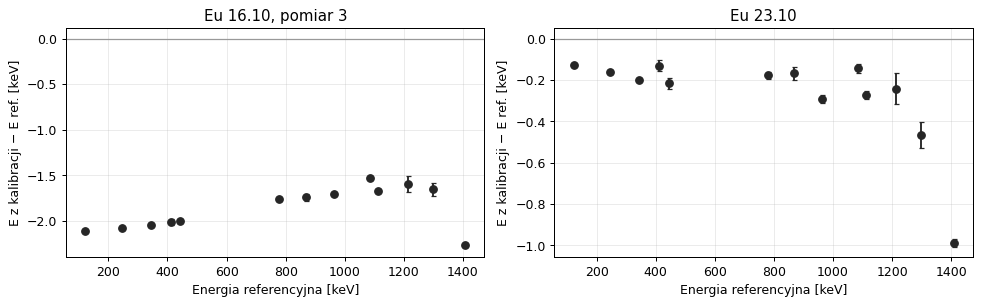

In [6]:
eu_lines=pd.DataFrame([
    # Energia i intensywność [%] przepisane ze świadectwa BW/Z-62/154/17, s. 2.
    (121.8,28.4),(244.7,7.6),(344.3,26.6),(411.1,2.4),
    (444.0,3.1),(778.9,13.0),(867.4,4.2),(964.1,14.5),
    (1085.8,10.1),(1112.1,13.4),(1212.9,1.4),(1299.1,1.6),(1408.0,20.9)
],columns=["E_keV","I_proc"])
chosen=eu_lines.E_keV.tolist()  # wszystkie linie gamma podane w świadectwie
eu_fit=pd.DataFrame([fit_row("Eu-152",EU16,E) for E in chosen])
eu23_fit=pd.DataFrame([fit_row("Eu-152",EU23,E) for E in chosen])
display(eu_fit.drop(columns="fit").round(3))
comparison=pd.DataFrame({
    "E_ref_keV":chosen,
    "odchylenie_16.10_keV":eu_fit.E_clb_keV.to_numpy()-np.array(chosen),
    "odchylenie_23.10_keV":eu23_fit.E_clb_keV.to_numpy()-np.array(chosen)})
display(comparison.round(3))
print("16.10: mediana przesunięcia =",np.median(comparison["odchylenie_16.10_keV"]),"keV")

fig,axs=plt.subplots(1,2,figsize=(11,3.5))
for ax,frame,label in [(axs[0],eu_fit,"Eu 16.10, pomiar 3"),(axs[1],eu23_fit,"Eu 23.10")]:
    ax.axhline(0,color="0.6",lw=1)
    ax.errorbar(frame.E_ref_keV,frame.E_clb_keV-frame.E_ref_keV,
                yerr=(a1*frame.u_kanal),fmt="o",color="0.15",capsize=2)
    ax.set(title=label,xlabel="Energia referencyjna [keV]",ylabel="E z kalibracji − E ref. [keV]")
plt.tight_layout()
plt.show()

### Pole piku Eu po odjęciu tła

Od zliczeń Eu odejmujemy długi pomiar tła, przeskalowany stosunkiem czasów żywych. Do widma po odjęciu tła dopasowujemy Gaussa i proste lokalne kontinuum; raportujemy wyłącznie niepewność **pola netto** $u(N)$ uzyskaną z dopasowania. Pojedyncze surowe zliczenia pozostają liczbami całkowitymi.

Eu i tło były rejestrowane w różnych dniach. W widmie Eu centra linii są przesunięte o około 2 keV względem referencji; odejmowanie według numeru kanału jest przybliżeniem. Dlatego podajemy też porównanie pól z wariantem tylko z lokalnym kontinuum. Dla linii bez istotnego piku tła różnica jest mała; nie traktujemy tego jako precyzyjnego wyrównania dwóch osi energii.

In [7]:
alpha_eu=EU16["live"]/BG["live"]
def area_after_background(spec, reference_fit):
    f=reference_fit["fit"]
    x=f["x"]
    k=x.astype(int)
    n=spec["counts"][k].astype(float)
    b=BG["counts"][k].astype(float)
    alpha=spec["live"]/BG["live"]
    z=n-alpha*b
    weights=1/np.sqrt(np.maximum(n+alpha**2*b,1))
    def model(q):
        A,mu,sig,B,slope=q
        return (A*(ndtr((x+.5-mu)/sig)-ndtr((x-.5-mu)/sig))
                +B+slope*(x-f["mu"]))
    q0=[f["A"],f["mu"],f["sigma"],f["bg"]-alpha*np.median(b),f["slope"]]
    lo=[0.,f["mu"]-2.,.35,-np.inf,-np.inf]
    hi=[1e7,f["mu"]+2.,6.,np.inf,np.inf]
    fit=least_squares(lambda q:(z-model(q))*weights,q0,bounds=(lo,hi),max_nfev=5000)
    u_N=np.sqrt(max(np.linalg.pinv(fit.jac.T@fit.jac)[0,0],0))
    A,mu,sig,B,slope=fit.x
    continuum=B+slope*(x-f["mu"])
    return dict(E_keV=reference_fit["E_ref_keV"],N_lokalne=f["A"],
                N_netto=fit.x[0],u_N_netto=u_N,
                zmiana_N=fit.x[0]-f["A"],
                zmiana_w_jednostkach_u=(fit.x[0]-f["A"])/f["u_A"],
                x=x,y_net=z,pred_net=model(fit.x),continuum_net=continuum)

eu_net=pd.DataFrame([area_after_background(EU16,row) for _,row in eu_fit.iterrows()])
display(eu_net.drop(columns=["x","y_net","pred_net","continuum_net"]).round(3))
print("Maksymalna zmiana dla linii do krzywej widoczna w tabeli; skala tła:",alpha_eu)

,E_keV,N_lokalne,N_netto,u_N_netto,zmiana_N,zmiana_w_jednostkach_u
0,121.8,31684.346,31705.594,186.654,21.248,0.114
1,244.7,5434.632,5441.973,83.973,7.341,0.087
2,344.3,14511.179,14527.718,125.250,16.539,0.132
3,411.1,1024.593,1026.071,41.128,1.478,0.036
4,444.0,1432.105,1435.053,45.324,2.948,0.065
5,778.9,3468.580,3467.031,63.556,-1.549,-0.024
6,867.4,1011.819,1017.563,39.370,5.744,0.146
7,964.1,3199.005,3201.105,59.903,2.100,0.035
8,1085.8,2032.115,2118.918,49.928,86.803,1.719
9,1112.1,2751.194,2757.334,55.666,6.140,0.110


Maksymalna zmiana dla linii do krzywej widoczna w tabeli; skala tła: 0.007536817788045048


### Podgląd dopasowań wszystkich linii Eu

Czarna schodkowa linia przedstawia surowe zliczenia. Zielona pokazuje długie tło pomnożone przez stosunek czasów żywych, niebieska to tło wraz z lokalnym kontinuum, a czerwona jest pełnym dopasowaniem. Pola w nagłówkach to wyniki dopasowania **po odjęciu tła**. Oś energii zachowuje kalibrację zapisaną w pliku, dlatego położenia pików Eu z 16.10 są przesunięte o około 2 keV względem energii referencyjnych w nagłówkach.

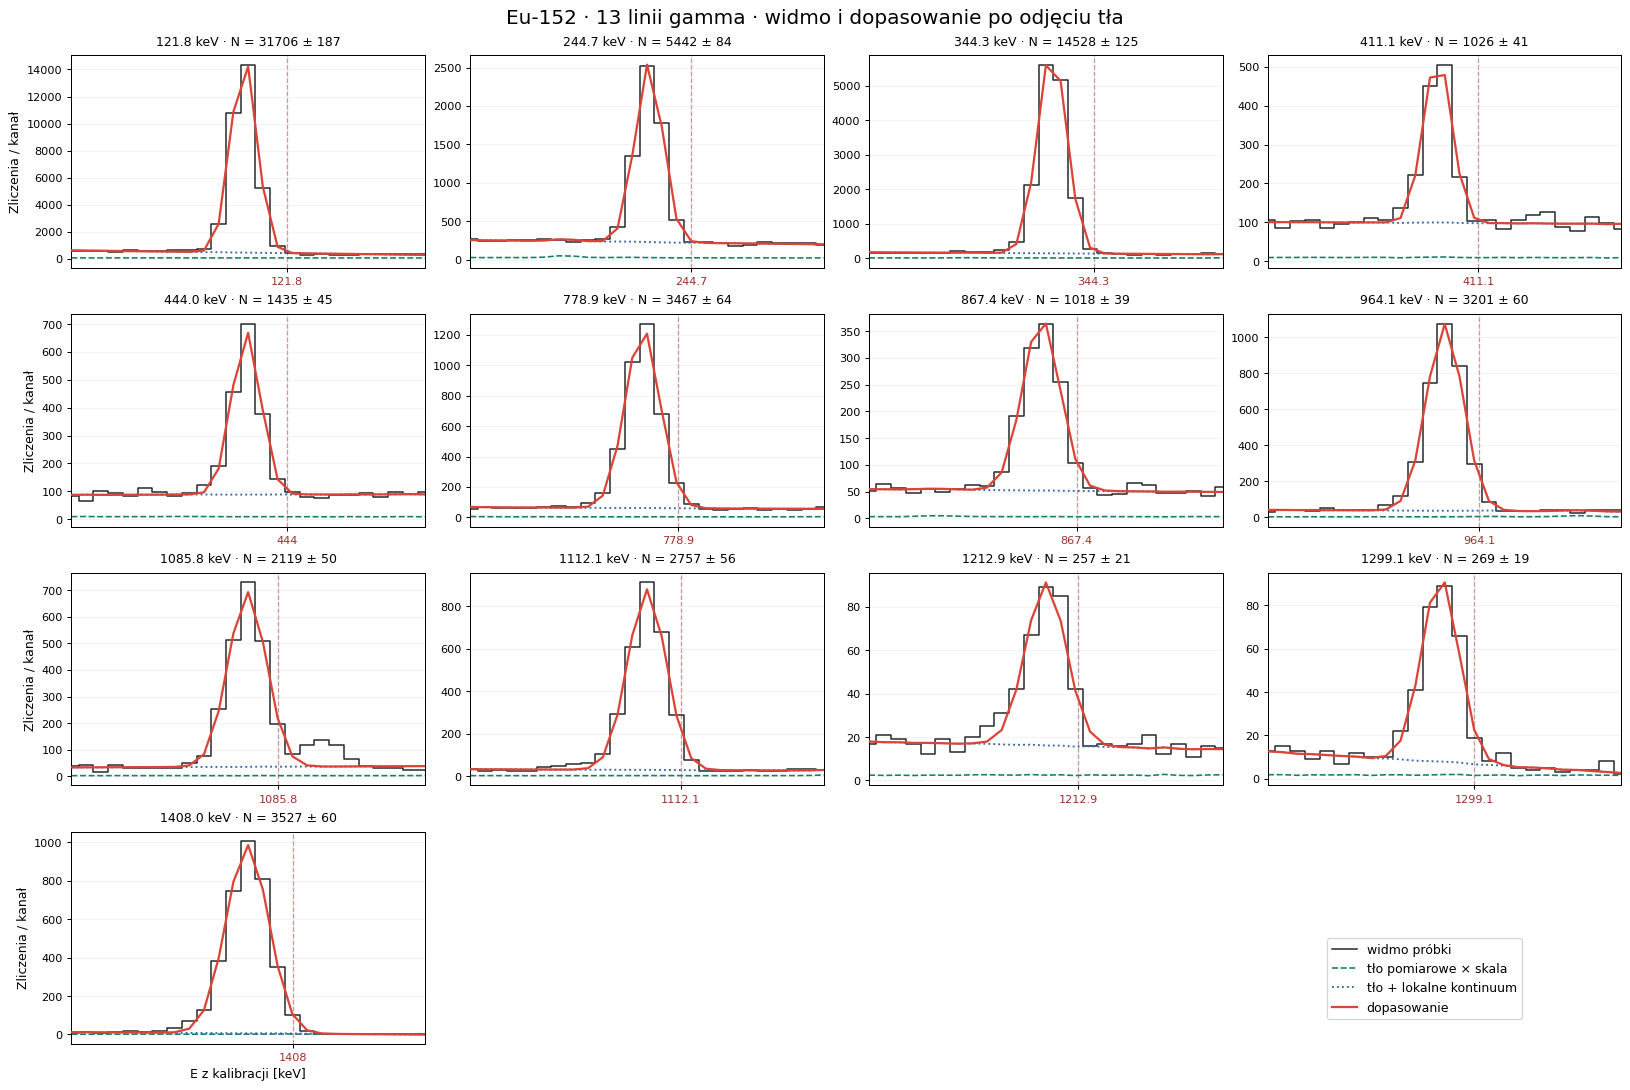

In [8]:
def draw_peak_components(ax,spec,net,title):
    channels=net["x"].astype(int)
    energy=spec["energy"][channels]
    raw=spec["counts"][channels].astype(float)
    scaled_background=BG["counts"][channels]*(spec["live"]/BG["live"])
    ax.step(energy,raw,where="mid",color="#22262b",lw=1.2,label="widmo próbki",zorder=2)
    ax.plot(energy,scaled_background,"--",color="#16806a",lw=1.3,label="tło pomiarowe × skala")
    ax.plot(energy,scaled_background+net["continuum_net"],":",color="#3468ae",lw=1.5,
            label="tło + lokalne kontinuum")
    ax.plot(energy,scaled_background+net["pred_net"],color="#db4437",lw=1.8,
            label="dopasowanie",zorder=3)
    ax.set_title(title,fontsize=10,pad=8)
    ax.set_xlim(energy.min(),energy.max())
    theory=float(net["E_keV"])
    if energy.min()<=theory<=energy.max():
        ax.axvline(theory,color="#ae4d42",ls="--",lw=1,alpha=.75,zorder=1)
        ax.set_xticks([theory])
        ax.set_xticklabels([f"{theory:g}"],color="#9b302b")
    ax.tick_params(labelsize=9)
    ax.grid(color="#d9dce0",alpha=.45,lw=.6)

fig,axs=plt.subplots(4,4,figsize=(18,12),constrained_layout=True)
for ax,(_,net) in zip(axs.flat,eu_net.iterrows()):
    title=f"{net['E_keV']:.1f} keV · N = {net['N_netto']:.0f} ± {net['u_N_netto']:.0f}"
    draw_peak_components(ax,EU16,net,title)
for ax in axs.flat[len(eu_net):]:
    ax.axis("off")
for row in axs:
    row[0].set_ylabel("Zliczenia / kanał",fontsize=10)
for ax in axs[-1]:
    if ax.axison: ax.set_xlabel("E z kalibracji [keV]",fontsize=10)
handles,labels=axs.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower right",bbox_to_anchor=(.94,.055),
           frameon=True,fontsize=10)
fig.suptitle("Eu-152 · 13 linii gamma · widmo i dopasowanie po odjęciu tła",fontsize=16)
plt.show()

## 4. Aktywność Eu i wydajność dla 16,9 cm

Aktywność w dniu 16.10.2026 oblicza się z $A=A_0 2^{-\Delta t/T_{1/2}}$. Świadectwo podaje $A_0=(101,3\pm2,4)$ kBq i $T_{1/2}=(13,522\pm0,016)$ roku, ale widoczna strona nie wyjaśnia współczynnika rozszerzenia niepewności. Wariant $k=1$ traktuje 2,4 kBq jako standardową, wariant $k=2$ jako rozszerzoną. Niepewności prawdopodobieństw $I_\gamma$ nie są dostępne w świadectwie; pokazane niepewności punktów są zatem **warunkowe**.

Dopasowanie z Z40 ma postać $\ln\varepsilon=c_3(\ln E)^3+c_2(\ln E)^2+c_1\ln E+c_0$ przy $E$ w keV. Model służy do interpolacji w obrębie linii Eu. Przyjęto $I_\gamma$ i czas żywy jako dokładne dane wejściowe. Niepewność punktowej wydajności obliczono z $u(N)$ i $u(A)$: $u(\varepsilon)=\varepsilon\sqrt{[u(N)/N]^2+[u(A)/A]^2}$. W geometrii kontaktowej wymaga to oddzielnego transferu.

Delta t=8.788655 roku; A_Eu=64558.63 Bq, u(A) przy k=1: 1529.91 Bq, przy k=2: 765.54 Bq
Zmiana względna aktywności w trakcie 526 s: 8.544096031792847e-07


,E_keV,I_proc,pole,u_pole,FWHM_keV,D_ndf,epsilon,u_stat_epsilon,u_cond_k1
0,121.8,28.4,31705.594268,186.653515,1.401278,6.963329,0.003313,0.000020,0.000081
1,244.7,7.6,5441.973456,83.972827,1.510817,1.196439,0.002125,0.000033,0.000060
2,344.3,26.6,14527.718022,125.250479,1.579166,4.189494,0.001621,0.000014,0.000041
3,411.1,2.4,1026.071274,41.128255,1.537592,2.057910,0.001269,0.000051,0.000059
4,444.0,3.1,1435.053089,45.323987,1.590257,1.625071,0.001374,0.000043,0.000054
5,778.9,13.0,3467.030710,63.556179,1.934345,1.464128,0.000791,0.000015,0.000024
6,867.4,4.2,1017.562958,39.369724,2.084954,0.963972,0.000719,0.000028,0.000033
7,964.1,14.5,3201.105068,59.902955,2.052581,2.145115,0.000655,0.000012,0.000020
8,1085.8,10.1,2118.918482,49.927787,2.057585,16.763834,0.000623,0.000015,0.000021
9,1112.1,13.4,2757.334021,55.666383,2.157959,3.509376,0.000611,0.000012,0.000019


Krzywa z wszystkich 13 linii Eu ze świadectwa.
Współczynniki c3,c2,c1,c0: [  0.06507508  -1.22150334   6.76458846 -17.23228712]
χ²/ndf (tylko niepewności pól): 1.4386399360045001
ε_Eu(411.8 keV), k=1: (np.float64(0.0013872216581815842), np.float64(6.459540464921914e-05))


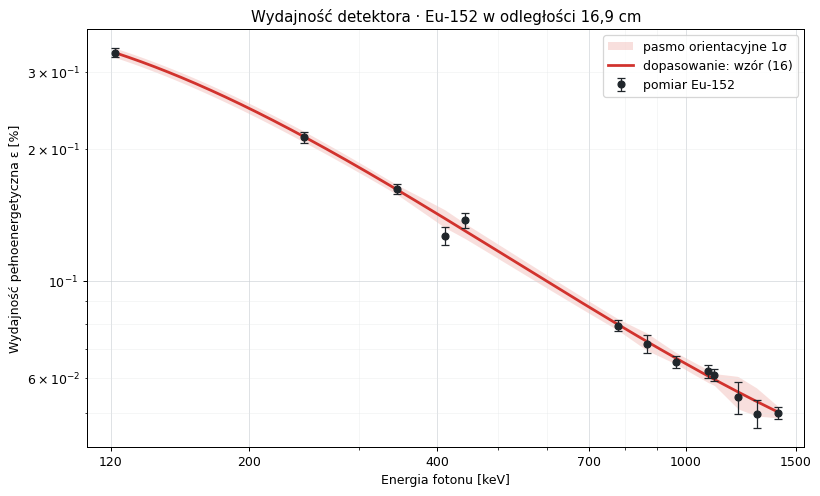

In [9]:
from datetime import timedelta
A0=101300.0
uA0_quoted=2400.0
T_year=13.522
uT_year=.016
t0=datetime(2018,1,1,12,0)
dt_year=(EU16["date"]-t0).total_seconds()/(365.25*86400)
activity=A0*2**(-dt_year/T_year)
def activity_uncertainty(k_factor):
    uA0=uA0_quoted/k_factor
    dA_dA0=activity/A0
    dA_dT=activity*np.log(2)*dt_year/T_year**2
    return np.hypot(dA_dA0*uA0,dA_dT*uT_year)
uA_k1=activity_uncertainty(1)
uA_k2=activity_uncertainty(2)
print(f"Delta t={dt_year:.6f} roku; A_Eu={activity:.2f} Bq, u(A) przy k=1: {uA_k1:.2f} Bq, przy k=2: {uA_k2:.2f} Bq")
print("Zmiana względna aktywności w trakcie 526 s:",1-np.exp(-np.log(2)*EU16["real"]/(T_year*365.25*86400)))

eu_points=eu_fit.merge(eu_lines,left_on="E_ref_keV",right_on="E_keV")
eu_points=eu_points.merge(eu_net[["E_keV","N_netto","u_N_netto"]],on="E_keV")
eu_points["pole"]=eu_points.N_netto
eu_points["u_pole"]=eu_points.u_N_netto
eu_points["epsilon"]=eu_points.pole/(activity*(eu_points.I_proc/100)*EU16["live"])
eu_points["u_stat_epsilon"]=eu_points.epsilon*eu_points.u_pole/eu_points.pole
eu_points["u_cond_k1"]=eu_points.epsilon*np.hypot(eu_points.u_pole/eu_points.pole,uA_k1/activity)
display(eu_points[["E_keV","I_proc","pole","u_pole","FWHM_keV","D_ndf",
                    "epsilon","u_stat_epsilon","u_cond_k1"]].round(6))
assert (eu_points.epsilon.between(0,1)).all()
print("Krzywa z wszystkich",len(eu_points),"linii Eu ze świadectwa.")

curve_points=eu_points
x=np.log(curve_points.E_keV.to_numpy())
y=np.log(curve_points.epsilon.to_numpy())
X=np.column_stack([x**3,x**2,x,np.ones_like(x)])
frac_stat=(curve_points.u_pole/curve_points.pole).to_numpy()
coef=np.polyfit(x,y,3,w=1/frac_stat)
resid=(y-X@coef)/frac_stat
chi2_eff=float(resid@resid)
dof_eff=len(x)-4
print("Współczynniki c3,c2,c1,c0:",coef)
print("χ²/ndf (tylko niepewności pól):",chi2_eff/dof_eff)
def epsilon_at(E,k_factor=1):
    val=np.exp(np.polyval(coef,np.log(E)))
    closest=curve_points.iloc[np.argmin(abs(curve_points.E_keV.to_numpy()-E))]
    u_nearest=closest.u_pole/closest.pole
    uA=activity_uncertainty(k_factor)
    return val,val*np.hypot(u_nearest,uA/activity)
print("ε_Eu(411.8 keV), k=1:",epsilon_at(411.8))

Eplot=np.geomspace(curve_points.E_keV.min(),curve_points.E_keV.max(),500)
curve=np.exp(np.polyval(coef,np.log(Eplot)))
# Proste pasmo poglądowe: względne u punktów interpolowane po log(E).
# Nie oznacza ono pełnej niepewności modelu ani geometrii folii.
relative_band=np.interp(np.log(Eplot),np.log(curve_points.E_keV),
                        curve_points.u_cond_k1/curve_points.epsilon)
fig,ax=plt.subplots(figsize=(9,5.4),layout="constrained")
ax.fill_between(Eplot,100*curve*(1-relative_band),100*curve*(1+relative_band),
                color="#db4437",alpha=.17,lw=0,label="pasmo orientacyjne 1σ")
ax.plot(Eplot,100*curve,color="#d1322d",lw=2.2,label="dopasowanie: wzór (16)")
ax.errorbar(curve_points.E_keV,100*curve_points.epsilon,
            yerr=100*curve_points.u_cond_k1,fmt="o",ms=5.5,capsize=3,
            color="#20262b",ecolor="#20262b",elinewidth=1,
            label="pomiar Eu-152",zorder=4)
ax.set(xscale="log",yscale="log",xlim=(110,1550),
       xlabel="Energia fotonu [keV]",ylabel="Wydajność pełnoenergetyczna ε [%]",
       title="Wydajność detektora · Eu-152 w odległości 16,9 cm")
ax.set_xticks([120,200,400,700,1000,1500])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.grid(which="major",color="#cbd0d4",alpha=.6)
ax.grid(which="minor",color="#e3e6e8",alpha=.35)
ax.legend(frameon=True,loc="upper right")
plt.show()

## 5. Tło oraz piki folii Au i Cu

Tło ma 2048 kolejnych kanałów i starą kalibrację. W widmach folii pokazano tło przeskalowane przez $t_{l,\rm próbka}/t_{l,\rm tło}$. Pola obu folii wyznaczono po odjęciu tego tła, dopasowując Gaussa i lokalne kontinuum. W instrukcji linię 511 keV przypisano $^{64}\mathrm{Cu}$; wynik dla Cu zakłada, że cały pik netto pochodzi z tego nuklidu.

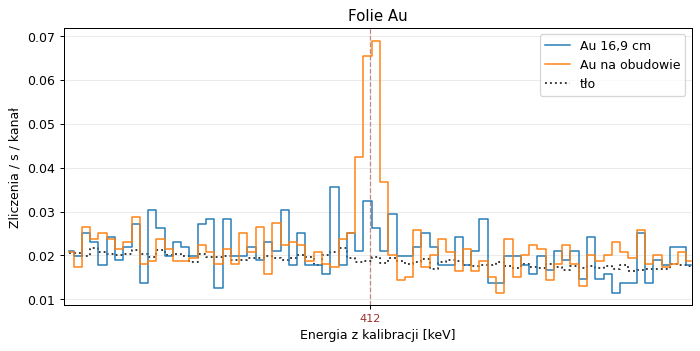

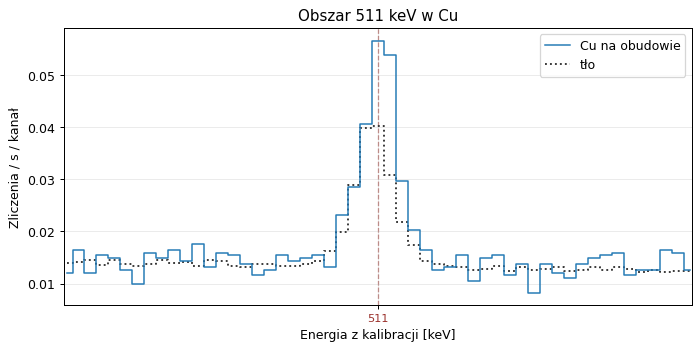

Au, pomiar z 16,9 cm: pik około 412 keV nie jest rozróżnialny od tła.


,widmo,E_fit_keV,N_netto,u_N
0,Au na obudowie,411.928,198.479,20.112
1,Cu na obudowie,511.141,91.964,19.455


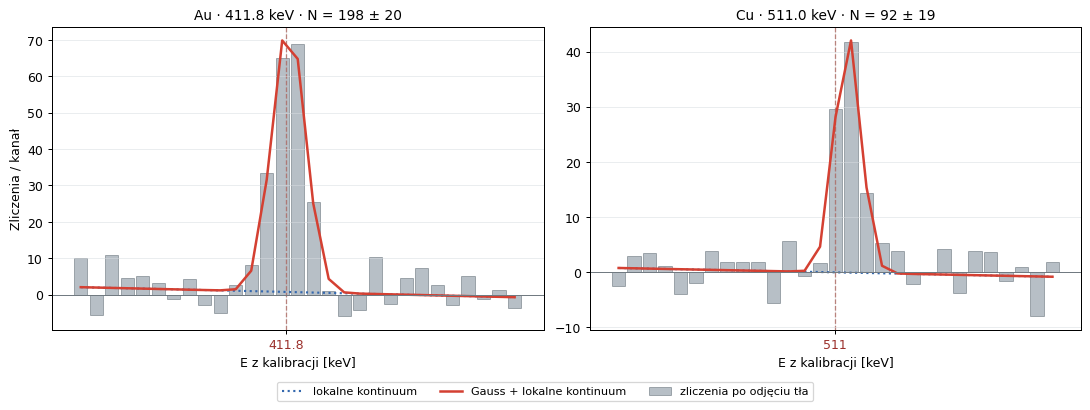

In [10]:
def overlay(specs, e_min, e_max, title, background=False, markers=()):
    fig,ax=plt.subplots(figsize=(9,4))
    for label,s in specs:
        m=(s["energy"]>=e_min)&(s["energy"]<=e_max)
        alpha=.43 if label=="Moneta 1" or label=="Cs na obudowie" else .98
        ax.step(s["energy"][m],s["counts"][m]/s["live"],where="mid",
                label=label,alpha=alpha,lw=.9 if "Moneta" in label else 1.2,
                zorder=4 if alpha<1 else 2)
    if background:
        m=(BG["energy"]>=e_min)&(BG["energy"]<=e_max)
        ax.step(BG["energy"][m],BG["counts"][m]/BG["live"],where="mid",
                color="0.2",linestyle=":",label="tło")
    ax.set(xlabel="Energia z kalibracji [keV]",ylabel="Zliczenia / s / kanał",title=title)
    for energy,label in sorted(markers):
        ax.axvline(energy,color="#aa5149",ls="--",lw=1,alpha=.72,zorder=1)
    if markers:
        ax.set_xticks([energy for energy,_ in sorted(markers)],
                      [label for _,label in sorted(markers)],fontsize=9,color="#9b302b")
    ax.set_xlim(e_min,e_max)
    ax.legend();plt.show()

overlay([("Au 16,9 cm",AU1),("Au na obudowie",AU2)],385,440,"Folie Au",True,
        markers=[(411.8,"412")])
overlay([("Cu na obudowie",CU)],492,530,"Obszar 511 keV w Cu",True,
        markers=[(511.,"511")])

print("Au, pomiar z 16,9 cm: pik około 412 keV nie jest rozróżnialny od tła.")
au2=fit_row("Au-198",AU2,411.8,window=14,tolerance=5)
net_au=area_after_background(AU2,au2)
au2["pole"],au2["u_pole"]=net_au["N_netto"],net_au["u_N_netto"]
cu511=fit_row("Cu-64 (511 keV)",CU,511.,window=14,tolerance=5)
net_cu=area_after_background(CU,cu511)
cu511["pole"],cu511["u_pole"]=net_cu["N_netto"],net_cu["u_N_netto"]
display(pd.DataFrame([
    dict(widmo="Au na obudowie",E_fit_keV=au2["E_clb_keV"],N_netto=au2["pole"],u_N=au2["u_pole"]),
    dict(widmo="Cu na obudowie",E_fit_keV=cu511["E_clb_keV"],N_netto=cu511["pole"],u_N=cu511["u_pole"])
]).round(3))
fig,axs=plt.subplots(1,2,figsize=(12,4.1),layout="constrained")
for ax,spec,net,label,E in [(axs[0],AU2,net_au,"Au",411.8),
                            (axs[1],CU,net_cu,"Cu",511.0)]:
    title=f"{label} · {E:.1f} keV · N = {net['N_netto']:.0f} ± {net['u_N_netto']:.0f}"
    channels=net["x"].astype(int)
    energy=spec["energy"][channels]
    width=np.median(np.diff(energy))*.86
    ax.bar(energy,net["y_net"],width=width,color="#7d8c98",alpha=.55,
           edgecolor="#34434e",lw=.55,label="zliczenia po odjęciu tła")
    ax.plot(energy,net["continuum_net"],":",color="#3468ae",lw=1.7,
            label="lokalne kontinuum")
    ax.plot(energy,net["pred_net"],color="#d44032",lw=2,
            label="Gauss + lokalne kontinuum")
    ax.axhline(0,color="#717a81",lw=.8)
    ax.axvline(E,color="#aa5149",ls="--",lw=1,alpha=.8,zorder=1)
    ax.set_xticks([E],[f"{E:g}"],color="#9b302b")
    ax.set_title(title,fontsize=11)
    ax.grid(axis="y",color="#d7dce0",alpha=.5)
    ax.set_xlabel("E z kalibracji [keV]")
axs[0].set_ylabel("Zliczenia / kanał")
handles,labels=axs[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(.5,-.09),ncol=3,fontsize=9)
plt.show()

## 6. Lokalny strumień neutronów z Au i Cu

Z40 używa modelu aktywacji cienkiej folii:

$$N_\gamma=\frac{t_l}{t_r}\,\varepsilon I_\gamma\,
\frac{\sigma\phi m g N_A}{M\lambda}
(1-e^{-\lambda t_a})e^{-\lambda t_c}(1-e^{-\lambda t_r}).$$

Z [Załącznika 3](../../instructions/Aktywacja_neutronowa_mat_dodatkowe.pdf) przyjęto dla Au: $\sigma=98,8$ b, $T_{1/2}=232675,2$ s, $g=1$, $I_\gamma=0,95$, $M=196,967$ g/mol. Dla reakcji $^{63}\mathrm{Cu}(n,\gamma)^{64}\mathrm{Cu}$ przyjęto $\sigma=4,5$ b, $T_{1/2}=46080$ s, $g=0,6915$, $I_{511}=0,38$, $M=62,93$ g/mol. Masy wynoszą $m_{\rm Au}=0,1328$ g i $m_{\rm Cu}=0,1479$ g. Czasy aktywacji to odpowiednio około 3,5 i 4 h; dla Cu przyjęto około 60 s chłodzenia. W tym uproszczonym rachunku $I_\gamma$, czasy żywe, masy i dane tablicowe są wartościami zadanymi. Niepewność liczbowa uwzględnia tylko $u(N)$ i $u(\varepsilon_{\rm Eu})$.

Karta detektora podaje odstęp okno–kryształ 3 mm oraz długość kryształu 70 mm. Dla przybliżenia odwrotnych kwadratów przyjmujemy środek kryształu za efektywną płaszczyznę rejestracji: $d_0=0,3+7,0/2=3,8$ cm. To **założenie obliczeniowe**, a nie odległość zmierzona do miejsca pochłonięcia fotonu. Samo $d_0=0,3$ cm dałoby $\varepsilon_{\rm Au}>1$ i nie może służyć do wyliczenia strumienia. Dla folii na obudowie:

$$G=\left(\frac{16,9+d_0}{d_0}\right)^2,\qquad
\varepsilon_{\rm folia}(E)=G\,\varepsilon_{\rm Eu}(E).$$

Wzór $1/r^2$ dla bliskiej geometrii jest przybliżeniem. Gotowa krzywa z Załącznika 1 dotyczy źródła objętościowego i nie odpowiada geometrii naszych pomiarów. Linia 511 keV jest anihilacyjna i nie jest swoista dla $^{64}\mathrm{Cu}$; przypisanie całego piku netto temu nuklidowi daje **warunkowy wynik Cu**, który może być obciążony dodatkowym wkładem. $\phi$ jest lokalną gęstością strumienia przy folii, nie emisją całego źródła AmBe.

In [11]:
N_A=6.02214076e23
m_Au=.1328
M_Au=196.967
g_Au=1.
sigma_Au=98.8e-24
T_Au=232675.2
I_Au=.95
lam_Au=np.log(2)/T_Au
E_Au=411.8
d_Eu=16.9
t_a_nom=3.5*3600
t_c_Au2=1084.

def flux_foil(area,epsilon,m,M,g,sigma,half_life,I,ta,tc,real,live):
    lam=np.log(2)/half_life
    return (area/epsilon/I * real/live
            *M*lam/(sigma*m*g*N_A)
            *np.exp(lam*tc)
            /(-np.expm1(-lam*ta))
            /(-np.expm1(-lam*real)))

eps_Eu,u_eps_Eu=epsilon_at(E_Au,1)
d0=.3+7.0/2  # cm: odstęp 3 mm + połowa długości kryształu 70 mm
G=((d_Eu+d0)/d0)**2
eps_Au=G*eps_Eu
assert 0<eps_Au<1, "Założona geometria daje niemożliwą wydajność."
phi_Au=flux_foil(au2["pole"],eps_Au,m_Au,M_Au,g_Au,sigma_Au,T_Au,I_Au,
                 t_a_nom,t_c_Au2,AU2["real"],AU2["live"])
u_phi_Au=phi_Au*np.hypot(au2["u_pole"]/au2["pole"],u_eps_Eu/eps_Eu)
print(f"d0={d0:.1f} cm; G={G:.3f}; ε_Eu(411,8)={eps_Eu:.6f}; "
      f"ε_Au(411,8)={eps_Au:.5f}")
print(f"Au: N=({au2['pole']:.1f} ± {au2['u_pole']:.1f}) zliczeń; "
      f"φ=({phi_Au:.0f} ± {u_phi_Au:.0f}) n cm^-2 s^-1 "
      "(niepewność warunkowa)")
eps_Cu_511,u_eps_Cu_511=epsilon_at(511.,1)
eps_Cu=G*eps_Cu_511
m_Cu=.1479
M_Cu=62.93
g_Cu=.6915
sigma_Cu=4.5e-24
T_Cu=46080.
I_Cu_511=.38
t_a_Cu=4*3600.
t_c_Cu=60.
phi_Cu=flux_foil(cu511["pole"],eps_Cu,m_Cu,M_Cu,g_Cu,sigma_Cu,T_Cu,I_Cu_511,
                 t_a_Cu,t_c_Cu,CU["real"],CU["live"])
u_phi_Cu=phi_Cu*np.hypot(cu511["u_pole"]/cu511["pole"],u_eps_Cu_511/eps_Cu_511)
print(f"Cu: ε_Eu(511,0)={eps_Cu_511:.6f}, ε_Cu(511,0)={eps_Cu:.5f}")
print(f"Cu: N=({cu511['pole']:.1f} ± {cu511['u_pole']:.1f}) zliczeń; "
      f"φ=({phi_Cu:.0f} ± {u_phi_Cu:.0f}) n cm^-2 s^-1 "
      "(niepewność warunkowa; cały pik przypisano Cu-64)")
print(f"φ_Cu/φ_Au={phi_Cu/phi_Au:.3f}; porównanie dotyczy przyjętych "
      "przekrojów i czasu aktywacji.")
print("3 mm bez uwzględnienia kryształu dawałoby ε_Au=",
      round(eps_Eu*((d_Eu+.3)/.3)**2,2),"> 1; tego wariantu nie użyto.")

d0=3.8 cm; G=29.674; ε_Eu(411,8)=0.001387; ε_Au(411,8)=0.04116
Au: N=(198.5 ± 20.1) zliczeń; φ=(2480 ± 277) n cm^-2 s^-1 (niepewność warunkowa)
Cu: ε_Eu(511,0)=0.001149, ε_Cu(511,0)=0.03409
Cu: N=(92.0 ± 19.5) zliczeń; φ=(4617 ± 994) n cm^-2 s^-1 (niepewność warunkowa; cały pik przypisano Cu-64)
φ_Cu/φ_Au=1.862; porównanie dotyczy przyjętych przekrojów i czasu aktywacji.
3 mm bez uwzględnienia kryształu dawałoby ε_Au= 4.56 > 1; tego wariantu nie użyto.


## 7. Widma pomocnicze

Widma Cs i Co rejestrowano przy różnych ustawieniach odległości, aby nauczyć się obsługi Tukana i obserwować zmianę częstości zliczeń oraz czasu martwego. Pozostałe widma pozwoliły sprawdzić zakres energii i zobaczyć linie próbek napromienionych neutronami. Pokazano je poglądowo bez wyznaczania pól pików ani prowadzenia osobnych analiz ilościowych. Wyjątek stanowią drugi pomiar Au i pomiar Cu, których pola są potrzebne do obliczenia strumieni.

W tabeli poniżej podano położenia wybranych maksimów **kanałowych**, a nie centroidy z dodatkowych dopasowań. Przyjęto $u_{\rm bin}=\Delta E/\sqrt{12}$ jako niepewność odczytu środka kanału przy równomiernym położeniu maksimum wewnątrz binu. Nie obejmuje ona niepewności kalibracji energetycznej, dryfu i wpływu dużego czasu martwego. Maksimum 511 keV monet nie identyfikuje samo przez się ich składu.

Czerwone wartości na osi energii i pionowe linie przerywane w poniższych widmach oznaczają energie tablicowe wybranych linii. W przypadku monet część tych linii występuje również w tle i nie identyfikuje materiału monety.

,widmo,E_ref_keV,E_max_keV,u_bin_keV
0,"Cs bliżej, pomiar 5",661.7,668.506,0.209
1,"Cs dalej, pomiar 1",661.7,661.975,0.209
2,"Co, pomiar 3",1173.2,1172.122,0.209
3,"Co, pomiar 3",1332.5,1330.318,0.209
4,"Mn, stary zakres",846.8,847.021,0.209
5,"Mn, nowy zakres",846.8,846.448,0.525
6,"Mn, nowy zakres",1810.7,1810.678,0.525
7,"Mn, nowy zakres",2113.1,2112.682,0.525
8,"Na, nowy zakres",511.0,511.696,0.525
9,"Na, nowy zakres",1274.6,1273.984,0.525


Au z większej odległości: nie zaobserwowano wyraźnego maksimum 412 keV.


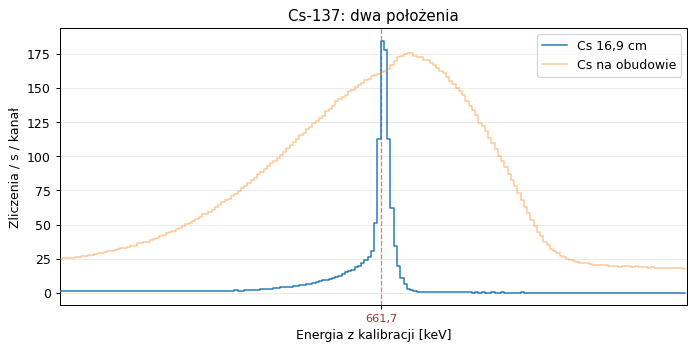

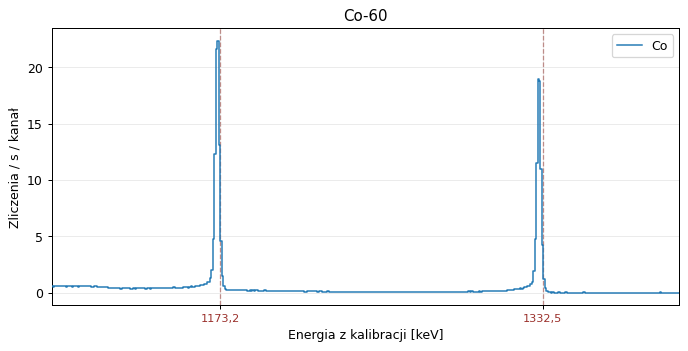

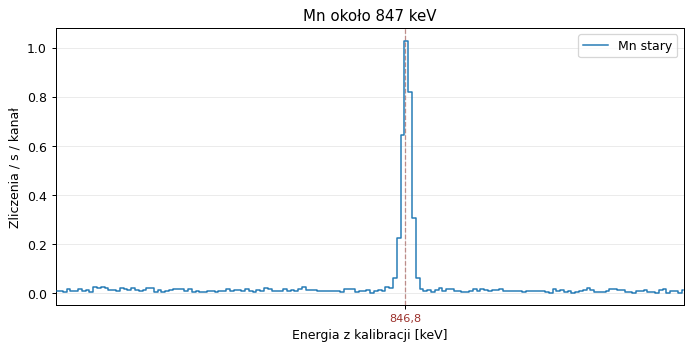

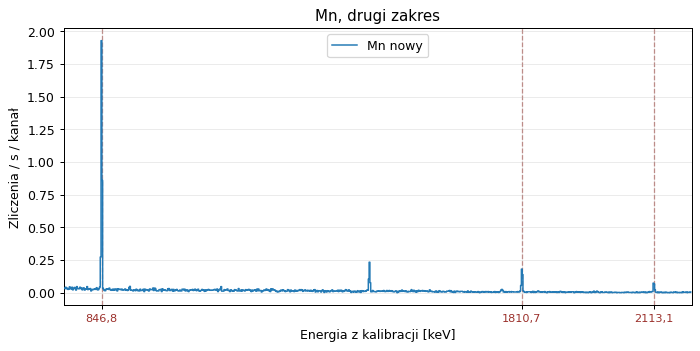

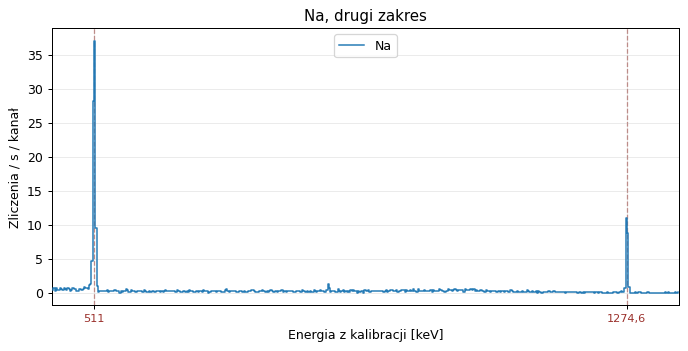

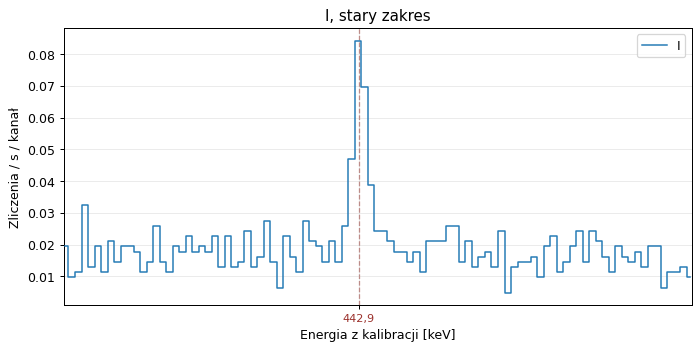

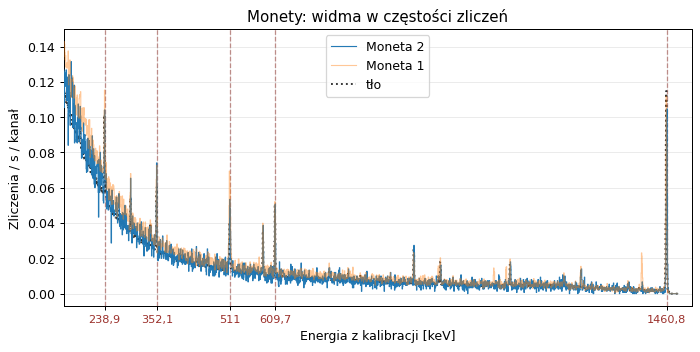

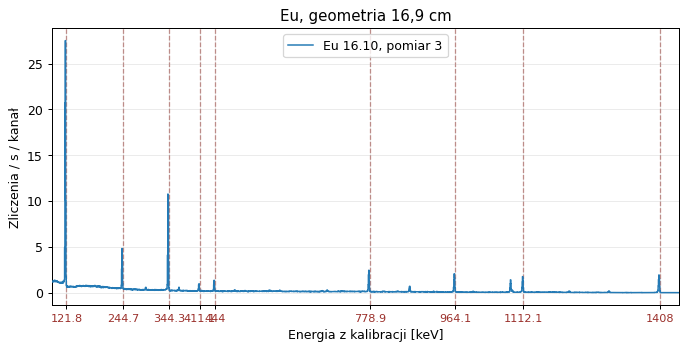

In [12]:
def observed_maximum(spec,reference_keV,span_keV=9):
    region=np.flatnonzero(abs(spec["energy"]-reference_keV)<=span_keV)
    if not len(region): raise ValueError("Brak kanałów w oknie")
    k=region[np.argmax(spec["counts"][region])]
    step=a2 if spec is MN2 or spec is NA else a1
    return float(spec["energy"][k]),float(step/np.sqrt(12))

aux_peaks=[
    ("Cs bliżej, pomiar 5",S("Cs137/Cs137_5_"),661.7),
    ("Cs dalej, pomiar 1",S("Cs137/Cs137_1_"),661.7),
    ("Co, pomiar 3",S("Co60/Co60_3_"),1173.2),
    ("Co, pomiar 3",S("Co60/Co60_3_"),1332.5),
    ("Mn, stary zakres",S("mangan/Mn_zakres_1."),846.8),
    ("Mn, nowy zakres",MN2,846.8),
    ("Mn, nowy zakres",MN2,1810.7),
    ("Mn, nowy zakres",MN2,2113.1),
    ("Na, nowy zakres",NA,511.0),
    ("Na, nowy zakres",NA,1274.6),
    ("I, stary zakres",S("jod/"),442.9),
    ("Moneta 1",COIN,511.0),
    ("Moneta 2",S("moneta2/"),511.0),
]
aux_peaks=pd.DataFrame([
    dict(widmo=name,E_ref_keV=ref,E_max_keV=observed_maximum(spec,ref)[0],
         u_bin_keV=observed_maximum(spec,ref)[1])
    for name,spec,ref in aux_peaks])
display(aux_peaks.round(3))
print("Au z większej odległości: nie zaobserwowano wyraźnego maksimum 412 keV.")

def marks_for(name):
    rows=aux_peaks.loc[aux_peaks.widmo==name]
    return [(float(r.E_max_keV),f"{r.E_max_keV:.0f}") for _,r in rows.iterrows()]

overlay([("Cs 16,9 cm",S("Cs137/Cs137_1_")),
         ("Cs na obudowie",S("Cs137/Cs137_5_"))],590,730,
        "Cs-137: dwa położenia",markers=[(661.7,"661,7")])
overlay([("Co",S("Co60/Co60_3_"))],1090,1400,"Co-60",
        markers=[(1173.2,"1173,2"),(1332.5,"1332,5")])
overlay([("Mn stary",S("mangan/Mn_zakres_1."))],780,900,"Mn około 847 keV",
        markers=[(846.8,"846,8")])
overlay([("Mn nowy",MN2)],760,2200,"Mn, drugi zakres",
        markers=[(846.8,"846,8"),(1810.7,"1810,7"),(2113.1,"2113,1")])
overlay([("Na",NA)],450,1350,"Na, drugi zakres",
        markers=[(511.,"511"),(1274.6,"1274,6")])
overlay([("I",S("jod/"))],410,480,"I, stary zakres",
        markers=[(442.9,"442,9")])
overlay([("Moneta 2",S("moneta2/")),("Moneta 1",COIN)],150,1515,
        "Monety: widma w częstości zliczeń",True,
        markers=[(238.9,"238,9"),(352.1,"352,1"),(511.,"511"),
                 (609.7,"609,7"),(1460.8,"1460,8")])
overlay([("Eu 16.10, pomiar 3",EU16)],90,1450,"Eu, geometria 16,9 cm",
        markers=[(float(r.E_ref_keV),f"{r.E_ref_keV:g}") for _,r in eu_fit.iterrows()
                 if r.E_ref_keV in (121.8,244.7,344.3,411.1,444.,778.9,964.1,1112.1,1408.)])

## 8. Rysunki do sprawozdania

Poniższa komórka zapisuje w katalogu `figures/` rysunki wykorzystane w sprawozdaniu. Zachowuje te same dane i dopasowania, które opisano powyżej. Podglądy wszystkich trzynastu dopasowań Eu pozostają we wcześniejszej komórce.

In [13]:
FIGURES=PROJECT/"figures"
FIGURES.mkdir(parents=True,exist_ok=True)
def save_report_figure(fig,name):
    fig.savefig(FIGURES/name,dpi=180,bbox_inches="tight",facecolor="white")
    print("Zapisano:",FIGURES/name)

# Sześć poglądowych widm w jednej planszy; czerwone punkty wskazują linie.
panels=[
    ([("Cs 16,9 cm",S("Cs137/Cs137_1_")),("Cs na obudowie",S("Cs137/Cs137_5_"))],590,730,"Cs: dwa położenia",[661.7]),
    ([("Co",S("Co60/Co60_3_"))],1090,1400,"Co",[1173.2,1332.5]),
    ([("Mn",S("mangan/Mn_zakres_1."))],780,900,"Mn: pierwszy zakres",[846.8]),
    ([("Mn",MN2)],760,2200,"Mn: drugi zakres",[846.8,1810.7,2113.1]),
    ([("Na",NA)],450,1350,"Na: drugi zakres",[511.,1274.6]),
    ([("I",S("jod/"))],410,480,"I: pierwszy zakres",[442.9]),
]
fig,axs=plt.subplots(3,2,figsize=(11.3,9.3),layout="constrained")
for ax,(samples,lo,hi,title,lines) in zip(axs.flat,panels):
    for label,s in samples:
        region=(s["energy"]>=lo)&(s["energy"]<=hi)
        ax.step(s["energy"][region],s["counts"][region]/s["live"],
                where="mid",label=label,lw=1.05,
                alpha=.46 if "na obudowie" in label else 1,
                zorder=4 if "na obudowie" in label else 2)
    for energy in lines:
        ax.axvline(energy,color="#aa5149",ls="--",lw=.95,alpha=.7,zorder=1)
    ax.set_xticks(lines,[f"{energy:g}" for energy in lines],
                  fontsize=8,color="#9b302b")
    ax.set(xlim=(lo,hi),title=title,xlabel="E [keV]",ylabel="Zliczenia / s / kanał")
    ax.tick_params(labelsize=8)
    ax.legend(fontsize=7,loc="upper right")
save_report_figure(fig,"widma_pomocnicze.png")
plt.show()

fig,ax=plt.subplots(figsize=(8,3.3),layout="constrained")
for label,s,color,alpha in [("Moneta 2",S("moneta2/"),"#d47528",1),
                             ("Moneta 1",COIN,"#2375ad",.46)]:
    region=(s["energy"]>=150)&(s["energy"]<=1515)
    ax.step(s["energy"][region],s["counts"][region]/s["live"],where="mid",
            color=color,lw=.85,alpha=alpha,label=label,
            zorder=4 if label=="Moneta 1" else 2)
region=(BG["energy"]>=150)&(BG["energy"]<=1515)
ax.step(BG["energy"][region],BG["counts"][region]/BG["live"],where="mid",
        linestyle=":",color=".15",lw=1,label="tło")
for energy,label in [(238.9,"239"),(352.1,"352"),(511.,"511"),
                     (609.7,"610"),(1460.8,"1461 (tło)")]:
    ax.axvline(energy,color="#aa5149",ls="--",lw=.9,alpha=.7,zorder=1)
ax.set_xticks([238.9,352.1,511.,609.7,1460.8],
              ["238,9","352,1","511","609,7","1460,8"],
              fontsize=8,color="#9b302b")
ax.set(xlim=(150,1515),xlabel="Energia z kalibracji [keV]",
       ylabel="Zliczenia / s / kanał",title="Widma dwóch monet")
ax.legend(fontsize=8)
save_report_figure(fig,"monety.png")
plt.show()

fig,axs=plt.subplots(2,2,figsize=(9,6.7),layout="constrained")
for ax,E in zip(axs.flat,[121.8,411.1,778.9,1408.0]):
    net=eu_net.loc[np.isclose(eu_net.E_keV,E)].iloc[0]
    draw_peak_components(ax,EU16,net,f"{E:.1f} keV: N={net.N_netto:.0f}±{net.u_N_netto:.0f}")
    ax.set(xlabel="E z kalibracji [keV]",ylabel="Zliczenia / kanał")
handles,labels=axs.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",ncol=2,fontsize=8,bbox_to_anchor=(.5,-.03))
save_report_figure(fig,"eu_dopasowania.png")
plt.show()

fig,ax=plt.subplots(figsize=(6.4,4.2),layout="constrained")
ax.plot(Eplot,100*curve,color="#ba3b34",lw=2,label="dopasowanie")
ax.errorbar(curve_points.E_keV,100*curve_points.epsilon,
            yerr=100*curve_points.u_cond_k1,fmt="o",ms=4.4,capsize=2,
            color="black",ecolor="black",label="^{152}Eu")
ax.set(xscale="log",yscale="log",xlim=(110,1550),
       xlabel="Energia fotonu [keV]",ylabel="Wydajność ε [%]")
ax.grid(which="both",alpha=.24)
ax.legend(fontsize=8)
save_report_figure(fig,"wydajnosc_eu.png")
plt.show()

fig,axs=plt.subplots(1,2,figsize=(10.6,3.5),layout="constrained")
for ax,spec,net,label,E in [(axs[0],AU2,net_au,"Au",411.8),
                            (axs[1],CU,net_cu,"Cu",511.0)]:
    channels=net["x"].astype(int)
    energy=spec["energy"][channels]
    ax.bar(energy,net["y_net"],width=np.median(np.diff(energy))*.86,
           color="#95a5af",edgecolor="#34434e",lw=.5,label="po odjęciu tła")
    ax.plot(energy,net["pred_net"],color="#ba3b34",lw=1.8,label="Gauss + kontinuum")
    ax.plot(energy,net["continuum_net"],":",color="#3468ae",lw=1.5,label="kontinuum")
    ax.axhline(0,color=".4",lw=.7)
    ax.axvline(E,color="#aa5149",ls="--",lw=1,alpha=.8,zorder=1)
    ax.set_xticks([E],[f"{E:g}"],color="#9b302b")
    ax.set(xlabel="E z kalibracji [keV]",title=f"{label}: N={net['N_netto']:.0f}±{net['u_N_netto']:.0f}")
axs[0].set_ylabel("Zliczenia / kanał")
handles,labels=axs[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(.5,-.1),ncol=3,fontsize=8)
save_report_figure(fig,"folie_dopasowania.png")
plt.show()

Zapisano: /workspace/scratch/ca912ca0bf1b/z40_work/project/figures/widma_pomocnicze.png


Zapisano: /workspace/scratch/ca912ca0bf1b/z40_work/project/figures/monety.png


Zapisano: /workspace/scratch/ca912ca0bf1b/z40_work/project/figures/eu_dopasowania.png


Zapisano: /workspace/scratch/ca912ca0bf1b/z40_work/project/figures/wydajnosc_eu.png


Zapisano: /workspace/scratch/ca912ca0bf1b/z40_work/project/figures/folie_dopasowania.png


## Co można przenieść do sprawozdania po zatwierdzeniu analizy

- Widma pomocnicze pokazać poglądowo, opisując w 2–3 zdaniach cel rejestracji. Przy wybranych pikach podać energie maksimów z tabeli i niepewność odczytu środka kanału $\Delta E/\sqrt{12}$. Nie zamieszczać szczegółowych tabel dopasowań dla Cs, Co, Mn, Na, I i monet.
- Z Eu przedstawić pola netto i krzywą wydajności, a dla folii pola drugiego pomiaru Au i piku 511 keV Cu. Oba pola wykorzystać do osobnych obliczeń strumienia. W Cu podać przypisanie 511 keV do $^{64}\mathrm{Cu}$ zgodnie z instrukcją i założenie o pochodzeniu całego pola netto.
- Wydajności obu folii przeliczyć z Eu przez kwadrat odległości z $d_0=3,8$ cm. Wartość $d_0$ wynika z założenia środka kryształu jako efektywnej płaszczyzny, więc oba wyniki strumienia pozostają warunkowe.